**Group information**

| Family name | First name | Email address |
| ----------- | ---------- | ------------- |
|             |            |               |
|             |            |               |
|             |            |               |

# Latent semantic analysis - Solutions

This tutorial explores numerical representations of text and their use in regression tasks. It employs the [Measuring Hate Speech dataset](https://huggingface.co/datasets/ucberkeley-dlab/measuring-hate-speech) from [Kennedy et al. (2020)](https://arxiv.org/abs/2009.10277), which contains approximately 40,000 short social media comments sourced from YouTube, Twitter, and Reddit and annotated by around 8,000 annotators. The primary target variable is the standardised continuous `hate_speech_score`.

**Disclaimer**: This dataset contains explicit and potentially offensive language. If you are not comfortable working with this material, an alternative text classification dataset can be selected from [Kaggle](https://www.kaggle.com/datasets?search=text+classification)'s public repository.

In [1]:
# Google Colab
!pip install umap-learn

In [2]:
# Packages
import matplotlib.pyplot as plt
import nltk
import numpy as np
import os
import pandas as pd
import re
import requests
import shutil
import urllib
import umap

from sklearn import feature_extraction, decomposition, ensemble, metrics, pipeline
from tqdm import tqdm
tqdm.pandas()

# NLTK downloads
nltk.download('punkt',     quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)

True

In [3]:
# Utilities
def download_data() -> None:
    if os.getcwd().endswith('/data'):
        print('Data folder already exists')
    else:
        urllib.request.urlretrieve('https://www.dropbox.com/scl/fo/zue56r0tnxmkb32a7czsl/AN-7FoQAXYVta2MlieRBnq4?rlkey=vk5x6tv8y27c3s61gsb04kvlf&dl=1', 'data.zip')
        shutil.unpack_archive('data.zip', 'data')
        os.remove('data.zip')
        os.chdir('data')

In [4]:
# Execute on first run
# download_data()
os.chdir(os.path.expanduser('~/Library/CloudStorage/Dropbox/teaching/text_analysis/2_latent/latent_practice/hatespeech_data'))

**1. Descriptive statistics**

Load the `hate_speech.csv` dataset, display a sample of the text entries, and report descriptive statistics for the `hate_speech_score` variable.

In [5]:
dataset = pd.read_csv('hate_speech.csv').set_index('comment_id')

for text in dataset['text'].sample(3):
    print(f'Sample text: {text}\n')

print(dataset['hate_speech_score'].describe())

Sample text: All white people are pedophile enablers becuase white men lead the world in pedophiliia. From the church to the classroom.

Sample text: I would suck your cock.

Sample text: @AskAnshul @Malala awaiting your response. Or is it only for Muslim women that you speak?

count    39565.000000
mean        -0.943911
std          2.073087
min         -8.340000
25%         -2.330000
50%         -0.700000
75%          0.570000
max          6.300000
Name: hate_speech_score, dtype: float64


**2. Cleaning**

Preprocess the text by converting to lowercase, retaining only alphabetic tokens, removing stopwords, and applying lemmatisation.

In [6]:
def tokenizer(text):
    tokens = text.lower()
    tokens = nltk.tokenize.word_tokenize(tokens)
    tokens = [t for t in tokens if t.isalpha()]
    tokens = [t for t in tokens if t not in stopwords]
    tokens = [lemmatiser.lemmatize(t) for t in tokens]
    tokens = ' '.join(tokens)
    return tokens

stopwords  = nltk.corpus.stopwords.words('english')
lemmatiser = nltk.stem.WordNetLemmatizer()

dataset['tokens'] = dataset['text'].progress_apply(tokenizer)

100%|██████████| 39565/39565 [00:05<00:00, 6889.21it/s]


**3. Text vectorisation**

Apply TF–IDF using `feature_extraction.text.TfidfVectorizer`, removing terms that appear in fewer than 5 documents or in more than 90% of the corpus. Report the dimensionality and sparsity of the resulting representation.

In [7]:
TFIDF = feature_extraction.text.TfidfVectorizer(min_df=5, max_df=0.9)
X = TFIDF.fit_transform(dataset['tokens'])
X = pd.DataFrame(X.toarray(), index=dataset.index, columns=TFIDF.get_feature_names_out())

print(X.iloc[:5, :5])
print(f'Dimensions: {X.shape}')
print(f'Sparsity: {(X == 0).mean(axis=None):.2%}')

             aa   ab  abandon  abandoned  abc
comment_id                                   
1           0.0  0.0      0.0        0.0  0.0
2           0.0  0.0      0.0        0.0  0.0
3           0.0  0.0      0.0        0.0  0.0
4           0.0  0.0      0.0        0.0  0.0
5           0.0  0.0      0.0        0.0  0.0
Dimensions: (39565, 8221)
Sparsity: 99.86%


**4. Singular Value Decomposition**

Apply singular value decomposition to the TF–IDF matrix using `decomposition.TruncatedSVD`, retaining the first 100 components to compute document embeddings. Report the resulting dimensionality, sparsity, and the proportion of variance explained.

In [8]:
# Document coordinates
SVD = decomposition.TruncatedSVD(n_components=100, random_state=0)
Ed  = SVD.fit_transform(X.values)
Ed  = pd.DataFrame(Ed, index=X.index, columns=[f'lc{i+1:03d}' for i in range(Ed.shape[1])])

print(Ed.iloc[:5, :5])
print(f'Dimensions: {Ed.shape}')
print(f'Sparsity: {(Ed == 0).mean(axis=None):.2%}')
print(f'Explained variance: {SVD.explained_variance_ratio_.sum():.2%}')

               lc001     lc002     lc003     lc004     lc005
comment_id                                                  
1           0.169807 -0.244272 -0.016650 -0.277873 -0.331286
2           0.039701 -0.028693  0.008408  0.024193  0.008808
3           0.080807 -0.072405 -0.007601 -0.012170 -0.013231
4           0.066437 -0.048032  0.020758  0.017008  0.007277
5           0.106457 -0.103305 -0.002356  0.074181  0.034254
Dimensions: (39565, 100)
Sparsity: 0.06%
Explained variance: 20.48%


**5. Term loadings**

Extract the term representations from the SVD and, for a random selection of components, inspect the terms with the largest positive and negative loadings.

In [9]:
# Term coordinates
Ew = SVD.components_.T * SVD.singular_values_
Ew = pd.DataFrame(Ew, index=TFIDF.get_feature_names_out(), columns=[f'lc{i+1:03d}' for i in range(Ew.shape[1])])

# Term loadings
for name in Ew.sample(n=3, axis=1).columns:
    col = Ew[name].sort_values(ascending=False)
    print(f'\nComponent: {name}')
    print(f'\nTop positive:\n{col.head(3)}')
    print(f'\nTop negative:\n{col.tail(3)}')


Component: lc055

Top positive:
kill       3.113248
america    2.934305
good       1.851070
Name: lc055, dtype: float64

Top negative:
american   -1.924295
say        -2.306566
jew        -2.559271
Name: lc055, dtype: float64

Component: lc082

Top positive:
religion    2.462258
real        2.367317
sex         1.642475
Name: lc082, dtype: float64

Top negative:
way      -1.778816
life     -1.854540
retard   -2.232884
Name: lc082, dtype: float64

Component: lc005

Top positive:
woman    8.177127
url      2.957908
men      1.963219
Name: lc005, dtype: float64

Top negative:
people   -3.840714
white    -5.251523
nigga    -5.908794
Name: lc005, dtype: float64


**6. Document similarity**

Select a random document and use `metrics.pairwise.cosine_similarity` to identify the most similar document in the corpus. Display both the query document and its nearest neighbour.

In [10]:
# Document similarity
query = Ed.sample(1)
match = metrics.pairwise.cosine_similarity(query, Ed)
match = pd.Series(match.flatten(), index=Ed.index, name='similarity')
match = match.drop(index=query.index[0])
match = match.sort_values(ascending=False)

print(f'\nQuery text:\n{dataset['tokens'].loc[query.index[0]]}\n')
print(f'\nMatch text:\n{dataset['tokens'].loc[match.index[0]]}\n')


Query text:
know idea innately bigoted potential kill many innocent people allowed take hold continue hold public discourse think right poor homophobe like


Match text:
hxstoricalhenry thirteendoors two day u twice many mass shooting canada year people basically watch tv medium identical two diffs gun u think god given right kill anyone disagree like



**7. Latent space**

Apply the Uniform Manifold Approximation and Projection (UMAP) transformation (not covered in class) to embed the document vectors into a two-dimensional space that preserves local neighbourhood structure and approximates the global structure. Plot the resulting latent space using `matplotlib`.

/Users/goclem/Software/miniconda3/envs/deeplearning/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


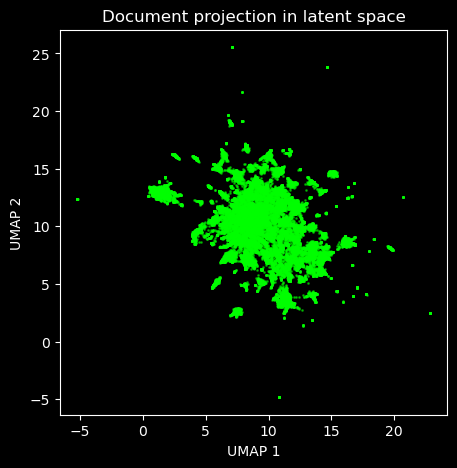

In [11]:
# UMAP projection (2D)
UMAP = umap.UMAP(n_components=2)
proj = UMAP.fit_transform(Ed)
proj = pd.DataFrame(proj, index=Ed.index, columns=['umap1', 'umap2'])
    
# Latent space plot
plt.style.use('dark_background')
plt.figure(figsize=(5, 5))
plt.scatter(proj['umap1'], proj['umap2'], s=1, alpha=0.5, color='lime')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('Document projection in latent space')
plt.show()

In [12]:
import plotly.express as px

# UMAP projection (3D)
UMAP = umap.UMAP(n_components=3, n_neighbors=50, min_dist=0.1)
proj = UMAP.fit_transform(Ed)
proj = pd.DataFrame(proj, index=Ed.index, columns=['umap1', 'umap2', 'umap3'])

# Latent space plot
fig = px.scatter_3d(
    proj.join(dataset['tokens']),
    x='umap1',
    y='umap2',
    z='umap3',
    hover_name='tokens',
    title='Document projection in latent space',
    labels={'umap1': 'UMAP 1', 'umap2': 'UMAP 2', 'umap3': 'UMAP 3'}
)
fig.update_traces(marker=dict(size=2, color='lime', line=dict(width=0.5, color='black')))
fig.update_layout(template='plotly_dark')
fig.write_html('document_umap_3d.html', include_plotlyjs='cdn')

/Users/goclem/Software/miniconda3/envs/deeplearning/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


**8. Text regression / classification**

Winsorise the `hate_speech_score`variable by clipping at the 1st and 99th percentiles, then discretise the resulting values into four categories using `pd.cut` with labels ['lovely', 'nice', 'quite rude', 'very rude'].

Fit a `ensemble.RandomForestClassifier` with 100 trees and `oob_score=True`, and evaluate the model's generalisation performance.

In [13]:
low, high = np.percentile(dataset['hate_speech_score'], [1, 99])

Yd = pd.cut(
    dataset['hate_speech_score'].clip(lower=low, upper=high),
    bins=4, 
    labels=['lovely', 'nice', 'quite rude', 'very rude'], 
    include_lowest=True)

model = ensemble.RandomForestClassifier(
    n_estimators=100, 
    n_jobs=-1, 
    oob_score=True, 
    random_state=0)

model.fit(Ed, Yd)
print(f'OOB R²: {model.oob_score_:.2%}')

OOB R²: 50.75%


**9. Fine-tuning**

Examine the effect of ensemble size on performance by fitting the model iteratively, starting with 10 trees and increasing the number of estimators in increments of 10 using `warm_start=True` to avoid refitting the entire model. 

/Users/goclem/Software/miniconda3/envs/deeplearning/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:612: UserWarning:

Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.



Trees:  10 | OOB R²: 0.4092


/Users/goclem/Software/miniconda3/envs/deeplearning/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:612: UserWarning:

Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.



Trees:  20 | OOB R²: 0.4498
Trees:  30 | OOB R²: 0.4704
Trees:  40 | OOB R²: 0.4800
Trees:  50 | OOB R²: 0.4904
Trees:  60 | OOB R²: 0.4946
Trees:  70 | OOB R²: 0.4984
Trees:  80 | OOB R²: 0.5018
Trees:  90 | OOB R²: 0.5046
Trees: 100 | OOB R²: 0.5075


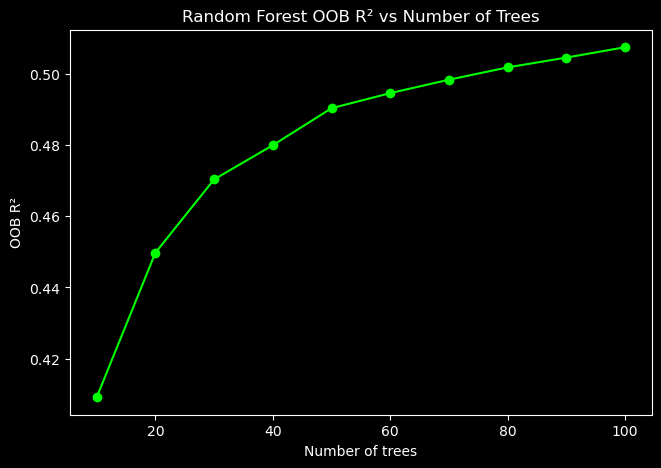

In [14]:
model = ensemble.RandomForestClassifier(
    n_jobs=-1, 
    oob_score=True, 
    warm_start=True, 
    random_state=0)

oobs = {}
max_trees, step = 100, 10
for n_estimators in range(step, max_trees + 1, step):
    model.set_params(n_estimators=n_estimators)
    model.fit(Ed.values, Yd.values)
    oobs[n_estimators] = model.oob_score_
    print(f'Trees: {n_estimators:3d} | OOB R²: {model.oob_score_:.4f}')

oobs = pd.Series(oobs)
plt.figure(figsize=(7.5, 5))
plt.plot(oobs.index, oobs.values, marker='o', color='lime')
plt.xlabel('Number of trees')
plt.ylabel('OOB R²')
plt.title('Random Forest OOB R² vs Number of Trees')
plt.show()
plt.close()

**10. Feature importance**

Using the model's `feature_importances_` attribute, plot the importance score for each predictor variable.

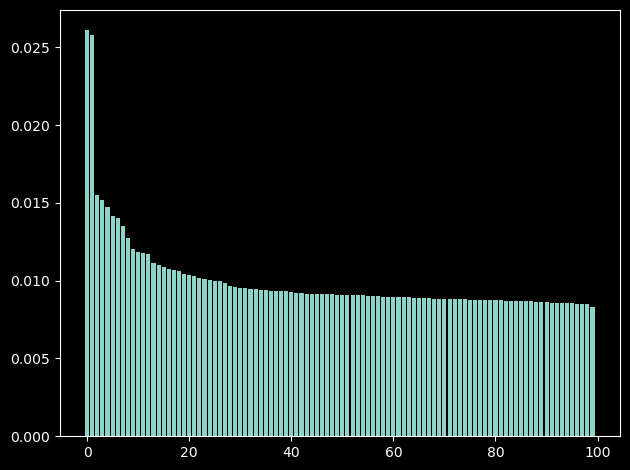

In [15]:

importances = pd.Series(model.feature_importances_, index=Ed.columns)
importances = importances.sort_values(ascending=False)

plt.figure()
plt.bar(range(len(importances)), importances.values)
plt.tight_layout()
plt.show()

**11. Prediction**

Test the model on your own text by applying the fitted TF-IDF and SVD transformations and then generating a prediction with the trained classifier. You may use `pipeline.Pipeline` to streamline the transformation and prediction steps.

In [16]:
text_pred = ['You are stupid!', 'You are amazing']

# Manually
X_pred  = TFIDF.transform(text_pred)
Ed_pred = SVD.transform(X_pred)
Yh_pred = model.predict(Ed_pred)

# Using pipeline
pipe    = pipeline.Pipeline([('tfidf', TFIDF), ('svd', SVD), ('model', model)])
Yh_pred = pipe.predict(text_pred)

for text, label in zip(text_pred, Yh_pred):
    print(f'Text: {text:<15} | Prediction: {label}')

Text: You are stupid! | Prediction: quite rude
Text: You are amazing | Prediction: lovely
